# 04 – Ensemble Model Development and Comparative Analysis (Part F & G)

This notebook builds the ensemble model from the two best base models developed in `03_Model_Development.ipynb`
and compares it against all three individual models.

**Approach**
- Same train/test split as notebook 02/03 (loaded from `dataset/processed/`).
- Same preprocessing pipelines as notebook 03.
- Base models rebuilt with the optimal hyperparameters found by GridSearchCV in notebook 03 (no re-tuning).
- Two models selected using the team's main evaluation metric (F1-score, see Section 1.5 of the report).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from time import perf_counter
from IPython.display import display

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Base models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ensemble techniques
from sklearn.ensemble import VotingClassifier, StackingClassifier

# Validation and evaluation
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load Training and Testing Datasets
The same stratified 80/20 split created in notebook 02 is used, so every model is trained and tested on identical data.

In [2]:
X_train = pd.read_csv("../dataset/processed/X_train.csv")
X_test = pd.read_csv("../dataset/processed/X_test.csv")

y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze("columns")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

Training features: (36168, 16)
Testing features: (9043, 16)

Training target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


## 2. Preprocessing Pipelines (same as notebook 03)
- **Logistic Regression**: median imputation + standard scaling for numerical features (LR is sensitive to feature scale).
- **Tree-based models**: median imputation only (trees split on thresholds, so scaling is not needed).
- **Categorical features**: most-frequent imputation + One-Hot Encoding.

`include=["object", "str"]` is used so the categorical columns are still detected in pandas 3 (where text columns use the `str` dtype).

In [3]:
categorical_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Numerical preprocessing for Logistic Regression
numerical_pipeline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for tree-based models
numerical_pipeline_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_lr, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_tree, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']


## 3. Rebuild the Optimised Base Models

The hyperparameters below are the `best_params_` found by GridSearchCV (5-fold stratified CV, scoring = F1) in notebook 03.
They are hardcoded so the grid searches do not need to be repeated.

| Model | Optimal hyperparameters (from notebook03) |
|---|---|
| Logistic Regression | C = 10, class_weight = balanced, solver = lbfgs |
| Random Forest | n_estimators = 300, max_depth = None, min_samples_split = 10, min_samples_leaf = 4, class_weight = balanced |
| Gradient Boosting | n_estimators = 200, learning_rate = 0.1, max_depth = 3, min_samples_leaf = 5 |

In [4]:
best_lr = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        C=10,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    ))
])

best_rf = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

best_gb = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        min_samples_leaf=5,
        random_state=42
    ))
])

## 4. Model Selection for the Ensemble (Part F)

The two models are selected using the **cross-validated F1-score** from the hyperparameter optimisation in notebook 03.
Cross-validation scores are used (instead of test-set scores) so that the test set is not used to make modelling decisions.

In [5]:
# Best cross-validation F1-scores reported by GridSearchCV in notebook 03
selection_table = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression", "Gradient Boosting"],
    "CV F1-Score (5-fold)": [0.4742, 0.3732, 0.3363]
}).sort_values("CV F1-Score (5-fold)", ascending=False)

selection_table["Rank"] = range(1, len(selection_table) + 1)
selection_table["Selected for Ensemble"] = ["Yes", "Yes", "No"]

display(selection_table.set_index("Model"))

,CV F1-Score (5-fold),Rank,Selected for Ensemble
Model,,,
Random Forest,0.4742,1,Yes
Logistic Regression,0.3732,2,Yes
Gradient Boosting,0.3363,3,No


**Selected:** Random Forest (rank 1) and Logistic Regression (rank 2).
**Excluded:** Gradient Boosting (lowest CV F1-score).

The two selected models are also different types of learner: Logistic Regression is a linear model, while Random Forest is a non-linear
bagging ensemble of decision trees. Models that learn in different ways tend to make different errors, which is the main reason
combining them can help.

## 5. Build the Ensemble – Soft Voting Classifier
**Soft voting** averages the predicted subscription probabilities of the two models and predicts "subscribe" when the average is ≥ 0.5.

Why soft voting instead of hard voting:
- Hard voting with only two models produces a tie whenever they disagree, and scikit-learn resolves ties in favour of class 0 (no subscription).
- Hard voting does not produce probabilities, so ROC-AUC cannot be calculated.
- Soft voting lets a confident model outweigh an uncertain one.

Each model keeps its own preprocessing pipeline, so Logistic Regression still receives scaled data and Random Forest does not.

In [6]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", best_lr),
        ("rf", best_rf)
    ],
    voting="soft"
)

start = perf_counter()
voting_model.fit(X_train, y_train)
voting_fit_seconds = perf_counter() - start

print(f"Soft Voting ensemble trained in {voting_fit_seconds:.2f} seconds")

Soft Voting ensemble trained in 1.19 seconds


## 6. Evaluation Helper
One function is used to evaluate every model the same way, so the comparison is fair.

In [7]:
def evaluate_model(name, model, fit_seconds):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time (s)": fit_seconds
    }

voting_results = evaluate_model("Soft Voting (RF + LR)", voting_model, voting_fit_seconds)
display(pd.DataFrame([voting_results]).set_index("Model").round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
Model,,,,,,
Soft Voting (RF + LR),0.8309,0.3658,0.6068,0.4565,0.7999,1.1922


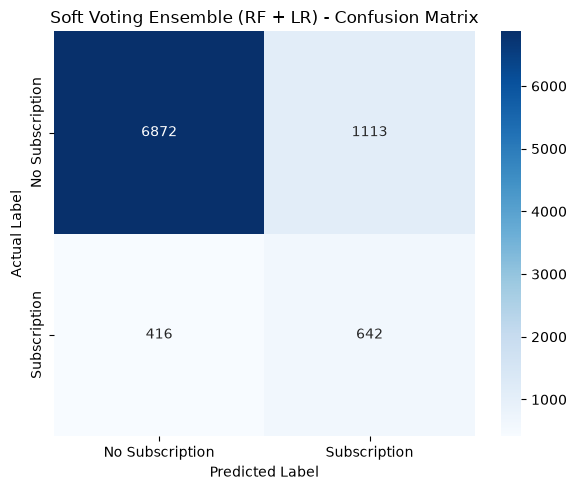

In [8]:
cm_voting = confusion_matrix(y_test, voting_model.predict(X_test))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_voting,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)
plt.title("Soft Voting Ensemble (RF + LR) - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 7. Alternative Ensemble – Stacking Classifier (comparison)

Stacking trains a **meta-learner** (here Logistic Regression) on the base models' predicted probabilities.
`cv=5` means the meta-learner is trained on *out-of-fold* predictions, so it never sees predictions the base models made on their own training data
(this prevents the meta-learner from over-trusting overfitted base models).

The meta-learner uses `class_weight="balanced"`, consistent with how class imbalance was handled for the base models (report Section 3.5).

In [9]:
stacking_model = StackingClassifier(
    estimators=[
        ("lr", best_lr),
        ("rf", best_rf)
    ],
    final_estimator=LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    stack_method="predict_proba",
    cv=5,
    n_jobs=-1
)

start = perf_counter()
stacking_model.fit(X_train, y_train)
stacking_fit_seconds = perf_counter() - start

stacking_results = evaluate_model("Stacking (RF + LR)", stacking_model, stacking_fit_seconds)
display(pd.DataFrame([stacking_results]).set_index("Model").round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
Model,,,,,,
Stacking (RF + LR),0.7919,0.3159,0.6682,0.429,0.8042,12.9282


## 8. Comparative Analysis – Base Models vs Ensemble (Part G)

All three optimised base models are retrained here with the same data, so that test metrics and training times are measured under identical conditions.

In [10]:
base_models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "Gradient Boosting": best_gb
}

all_results = []

for name, model in base_models.items():
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start
    all_results.append(evaluate_model(name, model, fit_seconds))

all_results.append(voting_results)
all_results.append(stacking_results)

comparison = pd.DataFrame(all_results).set_index("Model").round(4)
display(comparison)

comparison.to_csv("../results/ensemble_comparison.csv")
print("Saved to results/ensemble_comparison.csv")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
Model,,,,,,
Logistic Regression,0.7558,0.2670,0.6229,0.3738,0.7723,0.2525
Random Forest,0.8442,0.3913,0.5974,0.4729,0.8033,1.3441
Gradient Boosting,0.8957,0.6533,0.2316,0.3419,0.8065,11.9252
Soft Voting (RF + LR),0.8309,0.3658,0.6068,0.4565,0.7999,1.1922
Stacking (RF + LR),0.7919,0.3159,0.6682,0.4290,0.8042,12.9282


Saved to results/ensemble_comparison.csv


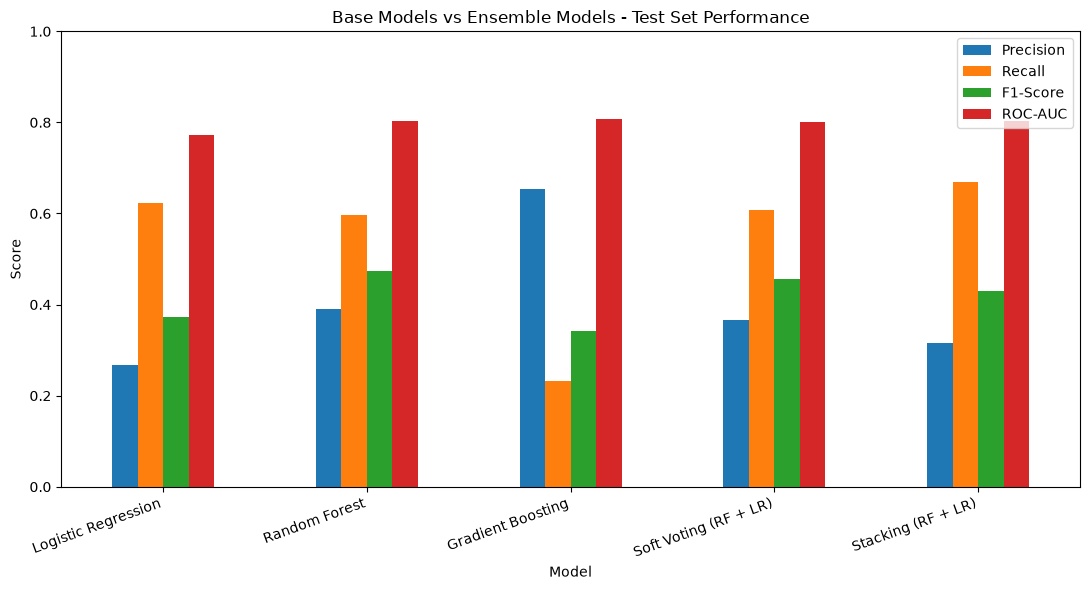

In [11]:
metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC"]

comparison[metrics_to_plot].plot(kind="bar", figsize=(11, 6))
plt.title("Base Models vs Ensemble Models - Test Set Performance")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../results/figures/ensemble_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.1 Confusion Matrices of All Models

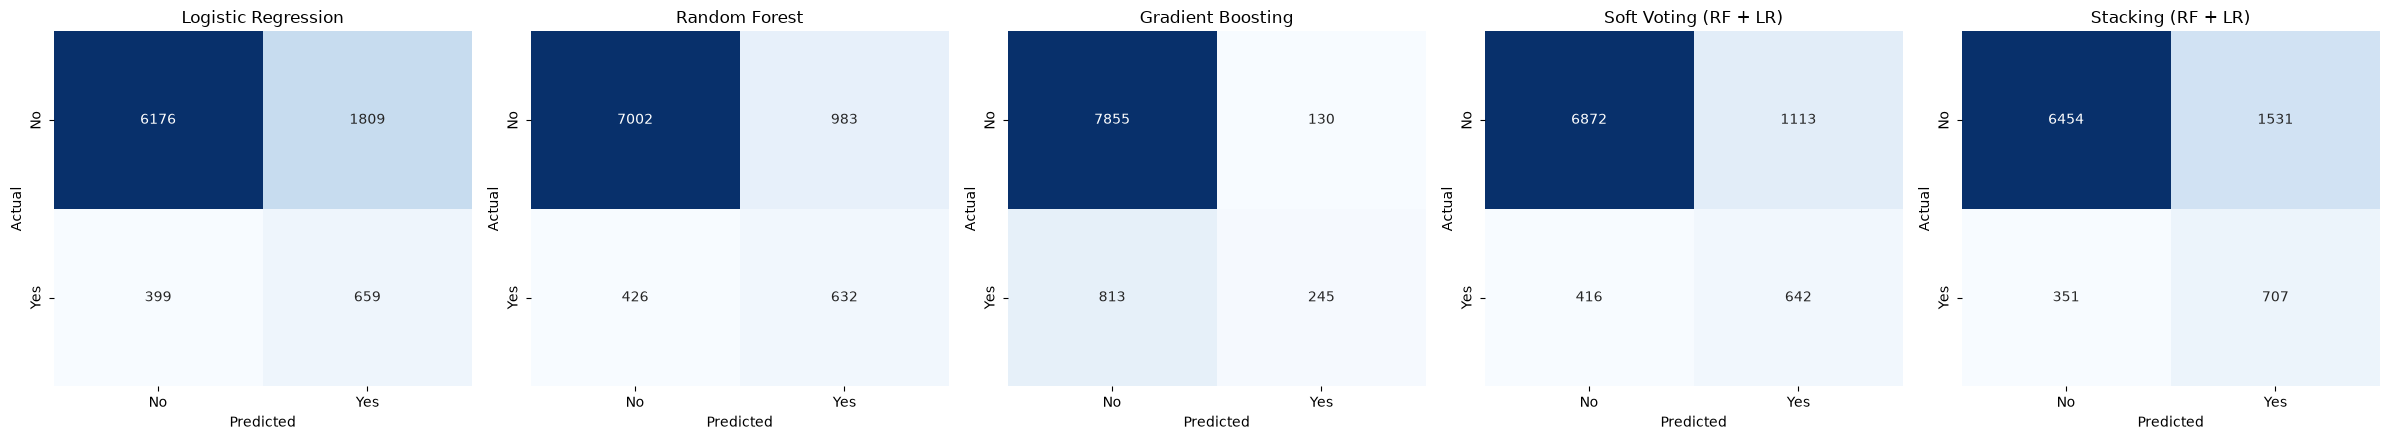

In [12]:
models_to_plot = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "Gradient Boosting": best_gb,
    "Soft Voting (RF + LR)": voting_model,
    "Stacking (RF + LR)": stacking_model
}

fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))

for ax, (name, model) in zip(axes, models_to_plot.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("../results/figures/ensemble_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.2 ROC Curves

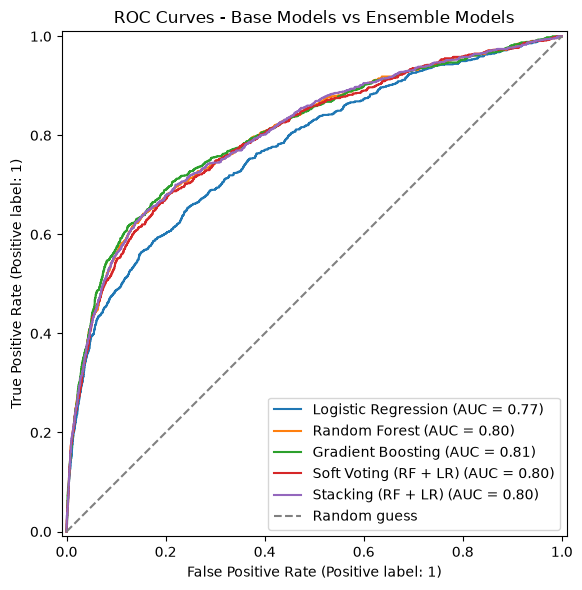

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models_to_plot.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_title("ROC Curves - Base Models vs Ensemble Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../results/figures/ensemble_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.3 Overfitting and Underfitting Check

A large gap between training F1 and test F1 indicates overfitting; low scores on both indicate underfitting.

In [14]:
fit_check = []

for name, model in models_to_plot.items():
    train_f1 = f1_score(y_train, model.predict(X_train))
    test_f1 = f1_score(y_test, model.predict(X_test))
    fit_check.append({
        "Model": name,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "Gap (Train - Test)": train_f1 - test_f1
    })

display(pd.DataFrame(fit_check).set_index("Model").round(4))

,Train F1,Test F1,Gap (Train - Test)
Model,,,
Logistic Regression,0.3767,0.3738,0.0029
Random Forest,0.6759,0.4729,0.2030
Gradient Boosting,0.3828,0.3419,0.0408
Soft Voting (RF + LR),0.5689,0.4565,0.1125
Stacking (RF + LR),0.5957,0.4290,0.1667


### 8.4 Is the Difference Consistent? (5-fold Cross-Validation)

A single test split can be lucky or unlucky, so the best base model and the ensemble are also compared with 5-fold stratified cross-validation
on the training set (same folds as notebook 03).

In [15]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rf = cross_val_score(best_rf, X_train, y_train, cv=cv_strategy, scoring="f1")
cv_voting = cross_val_score(voting_model, X_train, y_train, cv=cv_strategy, scoring="f1")

cv_summary = pd.DataFrame({
    "Model": ["Random Forest", "Soft Voting (RF + LR)"],
    "Mean CV F1": [cv_rf.mean(), cv_voting.mean()],
    "Std CV F1": [cv_rf.std(), cv_voting.std()]
}).set_index("Model").round(4)

display(cv_summary)
print("Fold-by-fold F1 (RF):    ", np.round(cv_rf, 4))
print("Fold-by-fold F1 (Voting):", np.round(cv_voting, 4))

,Mean CV F1,Std CV F1
Model,,
Random Forest,0.4625,0.0061
Soft Voting (RF + LR),0.4477,0.0057


Fold-by-fold F1 (RF):     [0.4622 0.4681 0.4693 0.4525 0.4602]
Fold-by-fold F1 (Voting): [0.4505 0.4551 0.4505 0.4423 0.44  ]


## 9. Findings (kena jawab ini)
1. **Performance differences** – which model has the highest F1 and ROC-AUC? How does the ensemble compare with Random Forest alone?
2. **Overfitting / underfitting** – use the train vs test F1 gap table.
3. **Computational efficiency** – use the training time column.
4. **Interpretability** – Logistic Regression coefficients are directly interpretable; Random Forest and the ensembles are much harder to explain.
5. **Does the ensemble significantly improve performance?** – compare the CV mean ± std of Random Forest and the ensemble.
6. **Recommendation for deployment** – based on the evidence above.